## Applications of SVD

- Compute the Pseudo-inverse of a matrix (used in training a ML model)
- Low-rank approximation (Image processing)

## Compute the pseudo-inverse

Recall: Let $A$ be a square matrix, if $\det(A)\ne 0$, then $A$ is invertible so $A^{-1}$ exists.

$$
A*A^{-1} = A^{-1}*A = I_n.
$$

Question: If matrix $A$ is not square or $\det(A) = 0$, what can we say about its inverse?

**Answer:** We cannot have the exact inverse, but we can define something similar to the acutal inverse.

**Thm:** Let $A$ be any matrix (size $m\times n$), then we can decompose it into
$$
A = U*\Sigma*V^T.
$$
We define
$$
A^{+} = V*\Sigma^{+}*U^T,
$$
then $A^{+}$ has some similar property as the actual inverse. It is called the pseudo inverse of $A$.

If $A$ has non-zero determinant, then $A^{+} = A^{-1}$.

What is $\Sigma^{+}$?

In [36]:
import numpy as np
import matplotlib.pyplot as plt

In [37]:
# Compute the Sigma^{+} from Sigma
# write a function to return a Sigma matrix
def gen_sigma(low=1, high=5, size=(4, 5), rank=3):
    S = np.zeros(size).astype(float)
    # generate the values on the diagonal
    v = np.random.uniform(low=low, high=high, size=rank)
    v = np.sort(v)[::-1] # sort and reverse
    # use sorted values in v to fill the diagonal
    for i in range(rank):
        if i < min(size):
            S[i, i] = v[i]

    return S

In [38]:
np.sort([1, 3, 2, 4])[::-1]

array([4, 3, 2, 1])

In [39]:
# create a Sigma matrix
S = gen_sigma(size=(20, 6), rank=4)
print(S)

[[4.7155572  0.         0.         0.         0.         0.        ]
 [0.         3.24586387 0.         0.         0.         0.        ]
 [0.         0.         2.46036844 0.         0.         0.        ]
 [0.         0.         0.         1.97672234 0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.        ]
 [0.         0.         0.        

In [40]:
# write a function to compute Sigma^{+}
def sigma_plus(S):
    A = np.zeros_like(S.T).astype(float)
    # fill the 1/sigma_i on the diagonal
    for i in range(min(S.shape)):
        sigma_i = S[i, i]
        if sigma_i != 0:
            A[i, i] = 1 / sigma_i
            
    return A

In [41]:
sigma_plus(S)

array([[0.21206402, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.30808439, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.40644319, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.50588794, 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0

In [42]:
# compute S and S^{+}
sigma_plus(S) @ S

array([[1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

In [43]:
# implement the pseudo-inverse
def pseudo_inverse(A):
    U, S, VT = np.linalg.svd(A, full_matrices=True)
    S1 = np.zeros(A.shape)
    for i, v in enumerate(S):
        S1[i, i] = v # fill the values on the diagonal
    S_plus = sigma_plus(S1)
    A_plus = VT.T @ (S_plus @ U.T)
    return A_plus

In [44]:
# test it!
A = np.random.randint(low=1, high=10, size=(100, 20))
print(A.shape)

(100, 20)


In [45]:
# compute its pseudo inverse
A_plus = pseudo_inverse(A)
print(A_plus.shape)

(20, 100)


In [46]:
A_plus

array([[ 2.42343287e-05, -3.61482562e-03,  7.65936894e-03, ...,
        -2.41875519e-03, -2.71579954e-03,  2.53637845e-03],
       [ 5.38173285e-04, -3.99654859e-03, -3.71801364e-03, ...,
        -2.13227377e-04,  1.29714047e-03,  1.49813133e-03],
       [ 9.90543200e-03, -3.88620627e-03,  1.02594210e-03, ...,
        -6.54592255e-03,  4.40116917e-03, -5.14285384e-03],
       ...,
       [-1.68577046e-03, -6.36205716e-03, -3.95363040e-03, ...,
         4.11872358e-03,  4.20950580e-04, -2.10521906e-03],
       [-5.29246432e-03,  8.82215647e-03,  9.29876400e-03, ...,
         1.10936625e-03,  3.16407921e-03, -2.13473051e-03],
       [ 1.89389746e-03, -5.73706094e-03, -6.43123706e-04, ...,
         1.39488086e-03, -3.51801642e-03, -2.01721869e-03]],
      shape=(20, 100))

## Low-rank approximation

**Thm:** Let $A$ be any matrix (size $m\times n$). We are looking for a matrix $A_k$ that has rank $k$ such that
$$
\|A-A_k\|
$$
is minimal.

If $A = U*\Sigma*V^T$, then the solution for the above problem is
$$
A_k = U_k * \Sigma_k * V_k^T,
$$

where $\Sigma_k$ is the truncated matrix from $\Sigma$

## Image processing
- Download an image online
- Use SVD to decompose the image
- Restruct the image with low-rank approximation

In [47]:
from PIL import Image

In [48]:
# convert to gray scale: "L"
# image must be in same folder
img = Image.open("img.jpg").convert("L")
# convert to numpy
img_arr = np.array(img)

In [49]:
print(img_arr.shape)

(425, 425)


In [50]:
U, S, VT = np.linalg.svd(img_arr, full_matrices=False)

In [51]:
# print the first 10 singular values
print(S[:10])

[53931.8520413  11542.5474001  10409.71454188  8358.40655772
  6765.59274283  6135.99233238  5444.22130549  5000.67467976
  3666.08847589  3512.54327053]


If we keep only 20 largest singular values of the image, how much information can we obtain?

**Recall:** Lower rank approximation.

Given matrix $A$, we decompose $A = U\sigma V^T$, where $\Sigma$ is the diagonal matrix with all singular values. Now we keep only $k=20$ values of $\Sigma$, set
$$
\Sigma_k = \Sigma[:k],
$$
and the first $k$ columns of $U$:
$$
U_k = U[:,:k]
$$
and also the last $k$ rows of $V^T$:
$$
V^T_k = V^T[:k,:]
$$
then we reconstruct the image as
$$
img_k = U_k*\Sigma_k*V^T_k.
$$

In [52]:
# set k
k = 20
# U, S, VT
U_k = U[:, :k]
S_k = np.diag(S[:k])
VT_k = VT[:k, :]

In [53]:
img_k = U_k @ (S_k @ VT_k)

Now we plot the approximated image vs the original one

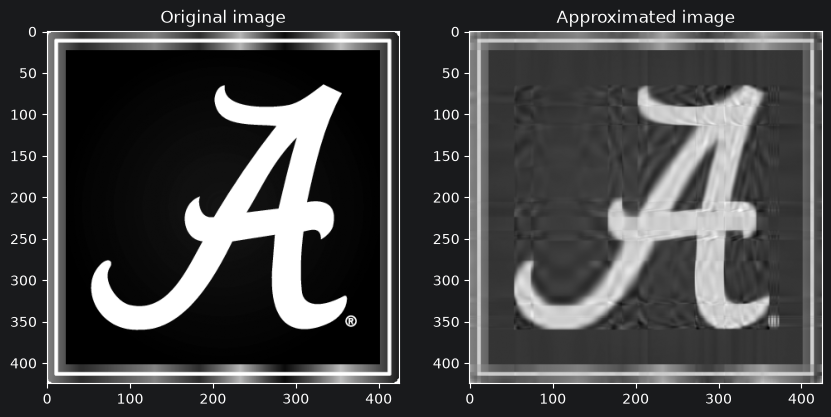

In [54]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 6))

# plot the original image
axs[0].imshow(img, cmap="gray") # set cmap="gray" to ignore colors
axs[0].set_title("Original image")

# plot the new one
axs[1].imshow(img_k, cmap="gray")
axs[1].set_title("Approximated image")
plt.show()

plt.show()

We will test with multiple values of the rank $k$ from $5$ to $100$ with step size $5$.

In [55]:
k_vals = np.arange(5, 101, 5)

In [56]:
print(k_vals.shape)

(20,)


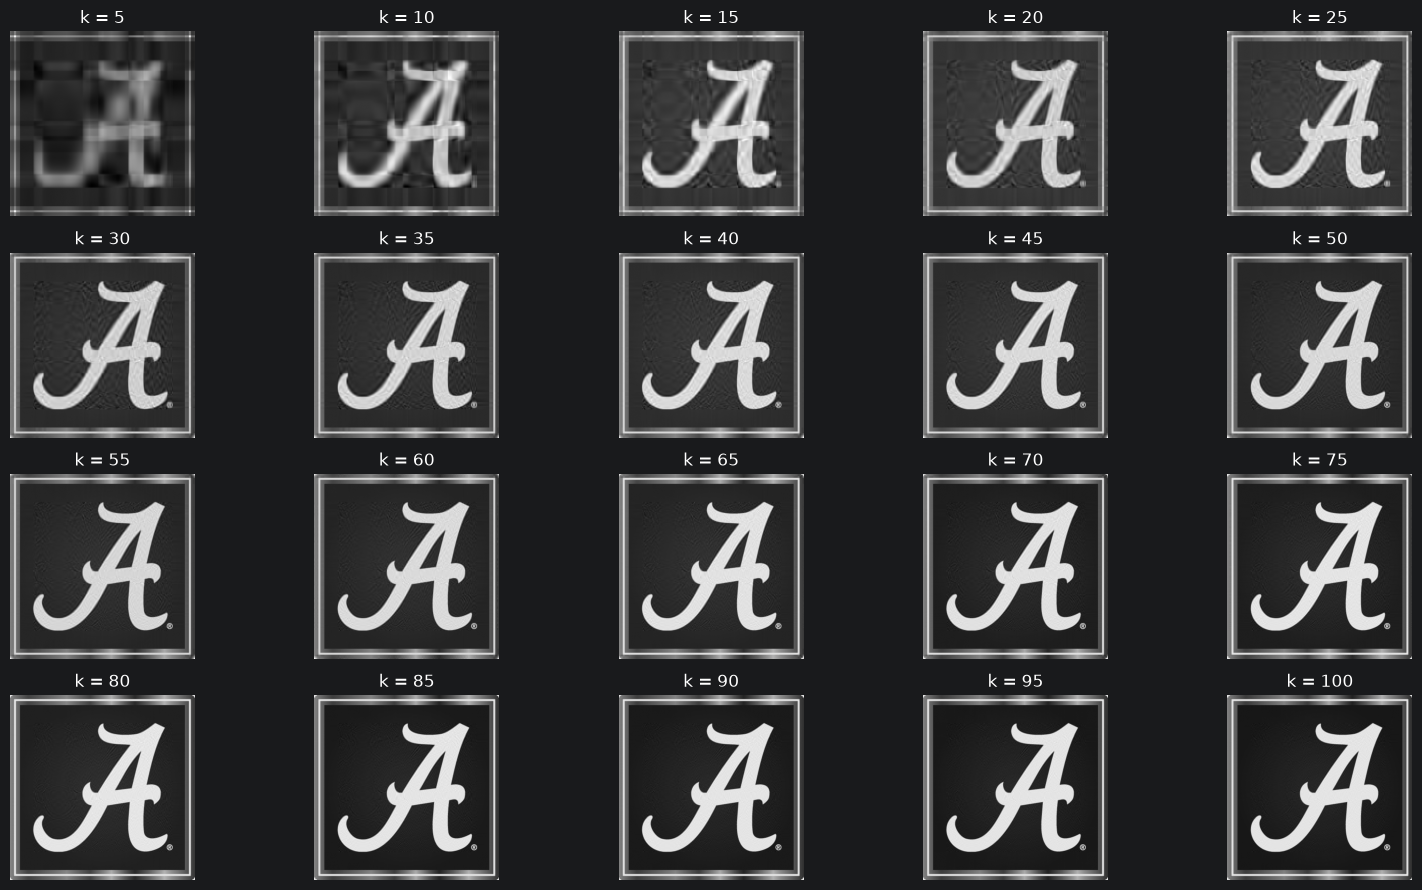

In [57]:
fig, axs = plt.subplots(nrows=4, ncols=5, figsize=(16, 9))

for i, k in enumerate(k_vals):
    # compute the row idx and col idx
    row_idx = i // 5 # quotient is the row index
    col_idx = i % 5 # remainder is the col index
    # compute the approximation for this k
    U_k = U[:, :k]
    S_k = np.diag(S[:k])
    VT_k = VT[:k, :]
    # reconstruct the image
    img_k = U_k @ (S_k @ VT_k)
    # plot this image at [row_idx, col_idx]
    axs[row_idx, col_idx].imshow(img_k, cmap="gray")
    axs[row_idx, col_idx].set_title(f"k = {k}")
    axs[row_idx, col_idx].set_axis_off()

# tight the layout
plt.tight_layout()
plt.show()

**Example:** Visualize the error for k-rank approximation.

- When $k$ is larger the $error_k$ must be smaller and goes to zero.

- Experiment with finite k values: $5 \le k \le 100$.

In [58]:
errors = []
for k in k_vals:
    # reconstruct the image
    U_k = U[:, :k]
    S_k = np.diag(S[:k])
    VT_k = VT[:k,:]
    # reconstruct the image
    img_k = U_k @ (S_k @ VT_k)
    # construct the error norm between
    # the approximation and original image.
    err = np.linalg.matrix_norm(img_arr - img_k)
    errors.append(err)

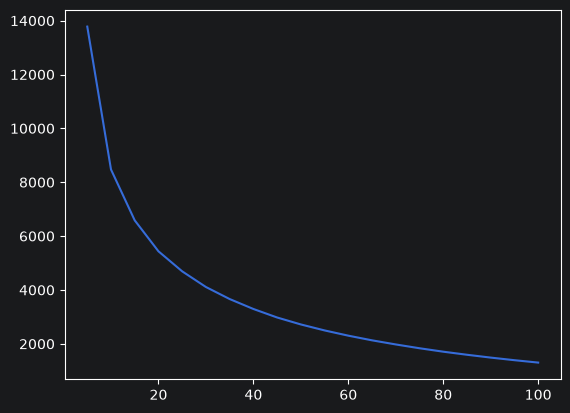

In [59]:
# plot the errors
fig, ax = plt.subplots()

ax.plot(k_vals, errors)

plt.show()

How much information can we keep when we use $k$-rank approximation of the image?

In [60]:
k = 35

In [61]:
# A = U * S * VT
total_variance = np.sum(S**2)
retained_var = np.sum(S[:k]**2)

In [62]:
# percentage of this approximation
percentage = (retained_var / total_variance) * 100
print(percentage)

99.61182600982646


Compute the accumulated variance of the matrix and plot the curve.

- The more singular values we keep, the higher the variance we can obtain
- With some threshold we can determine how many singular values we can stop.

In [63]:
accum_var = np.cumsum(S**2 / total_variance)

In [64]:
print(accum_var)

[0.8416839  0.88023721 0.91159432 0.93181079 0.94505634 0.95595136
 0.96452825 0.97176453 0.97565377 0.97922405 0.98156927 0.98338219
 0.98488337 0.98625878 0.98745828 0.98838926 0.98930401 0.99013814
 0.99082354 0.99145128 0.99196852 0.9924189  0.99283452 0.99323998
 0.993632   0.99397172 0.99428971 0.99460249 0.99486299 0.99511299
 0.99534986 0.99557004 0.99576811 0.99595084 0.99611826 0.99628388
 0.9964385  0.99658771 0.99672783 0.99686033 0.99698608 0.99710651
 0.99722092 0.99733095 0.99743436 0.9975273  0.99761779 0.99770097
 0.99778265 0.99785991 0.99793347 0.99800458 0.99807049 0.99813519
 0.99819509 0.9982532  0.99830874 0.99836284 0.99841559 0.99846566
 0.99851457 0.99856058 0.9986046  0.99864711 0.99868778 0.99872792
 0.99876592 0.99880186 0.99883638 0.99886907 0.99890156 0.9989338
 0.99896477 0.99899536 0.99902488 0.99905291 0.99908056 0.99910739
 0.99913214 0.99915601 0.99917937 0.99920208 0.99922371 0.9992446
 0.99926464 0.99928432 0.99930377 0.99932291 0.99934115 0.999358

In [65]:
sizes = np.arange(len(accum_var))

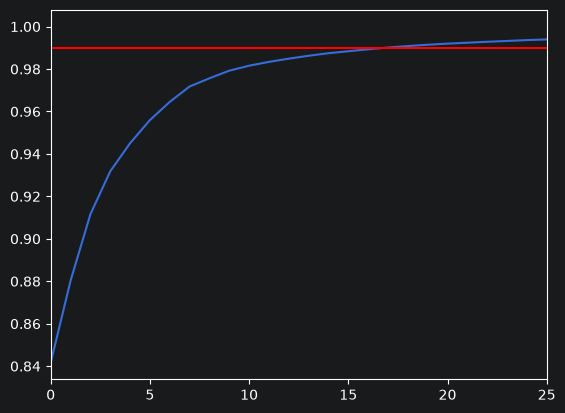

In [66]:
fig, ax = plt.subplots()

ax.plot(sizes, accum_var, label="Accumulative Variance")

ax.axhline(y=.99, color="red")

ax.set_xlim(0, 25)

plt.show()

Conclusion: we need to keep only 16 singular values to obtain $99\%$ of the image.

In [67]:
# determine the dimensions of the data when we cut off at k=16
k = 16
U_k = U[:, :k]
S_k = np.diag(S[:k])
VT_k = VT[:k,:]
# reconstruct the image
img_k = U_k @ (S_k @ VT_k)

In [68]:
# check the shape of the approximated image
print(img_k.shape)

(425, 425)
